In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-to-rule-them-all/train_labels.npy
/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-to-rule-them-all/class_names.npy
/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-to-rule-them-all/emb_clip_train.npy
/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-to-rule-them-all/sample_submission.csv
/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-to-rule-them-all/proposals_test.npy
/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-to-rule-them-all/train_images.npy
/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-to-rule-them-all/proposal_objness_test.npy
/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-to-rule-them-all/emb_clip_test.npy
/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-to-rule-them-all/config_public.json
/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-to-rule-them-all/train_gt_boxes.npy
/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import numpy as np
import pandas as pd
import json
import os

PATH = "/kaggle/input/competitions/cyprus-summer-ai-camp-one-crop-to-rule-them-all"

train_labels = np.load(f"{PATH}/train_labels.npy")
class_names = np.load(f"{PATH}/class_names.npy")
emb_clip_train = np.load(f"{PATH}/emb_clip_train.npy")

sample_sub = pd.read_csv(f"{PATH}/sample_submission.csv")

proposals_test = np.load(f"{PATH}/proposals_test.npy")
proposal_objness_test = np.load(f"{PATH}/proposal_objness_test.npy")
emb_clip_test = np.load(f"{PATH}/emb_clip_test.npy")
test_images = np.load(f"{PATH}/test_images.npy")

train_images = np.load(f"{PATH}/train_images.npy")
train_gt_boxes = np.load(f"{PATH}/train_gt_boxes.npy")
proposals_train = np.load(f"{PATH}/proposals_train.npy")
proposal_cost_train = np.load(f"{PATH}/proposal_cost_train.npy")
proposal_cost_test = np.load(f"{PATH}/proposal_cost_test.npy")
proposal_objness_train = np.load(f"{PATH}/proposal_objness_train.npy")

with open(f"{PATH}/config_public.json", "r") as f:
    config_public = json.load(f)

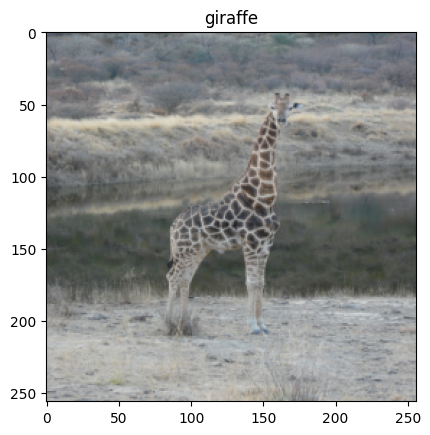

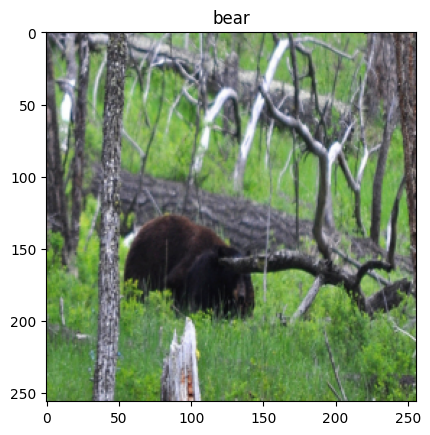

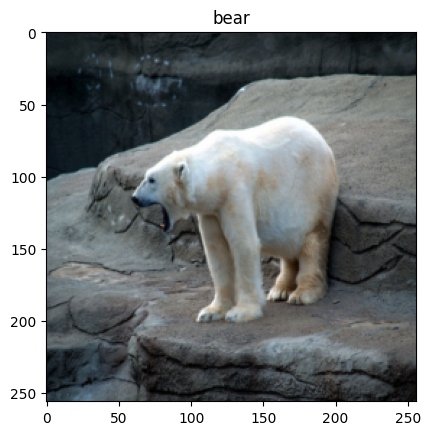

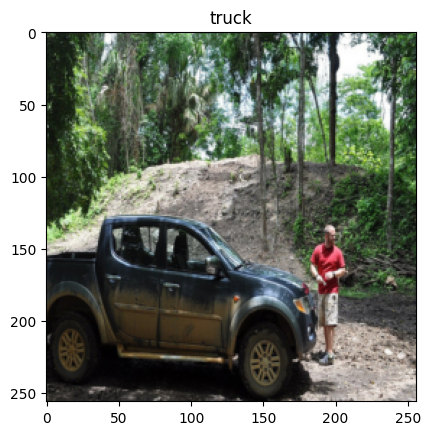

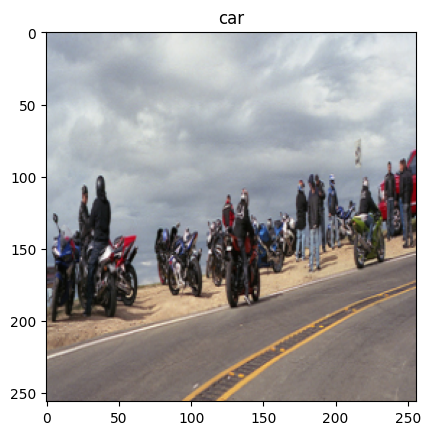

...

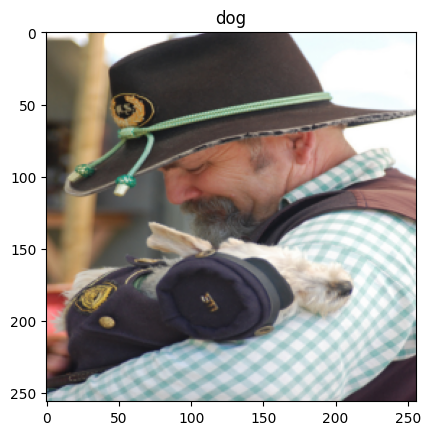

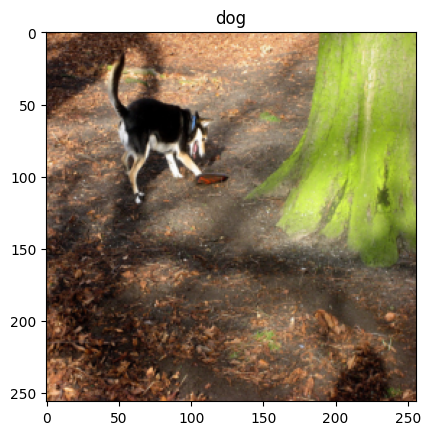

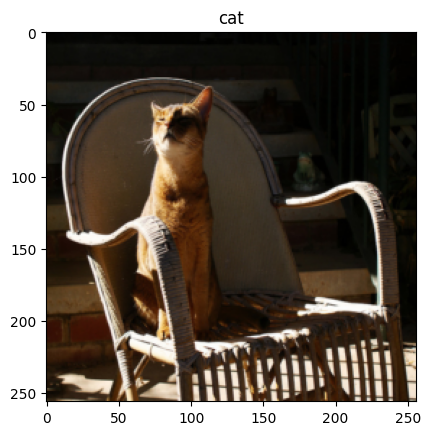

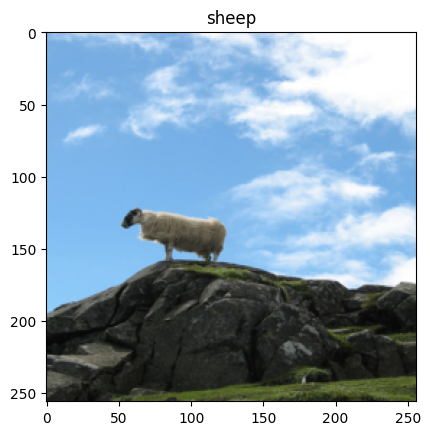

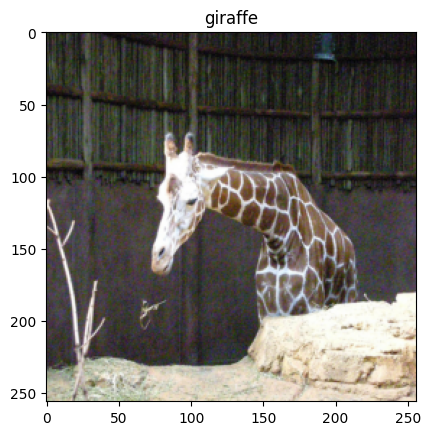

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
for i, img in enumerate(train_images):
    plt.imshow(img);plt.title(class_names[train_labels[i]])
    plt.show()
    if i>10:break

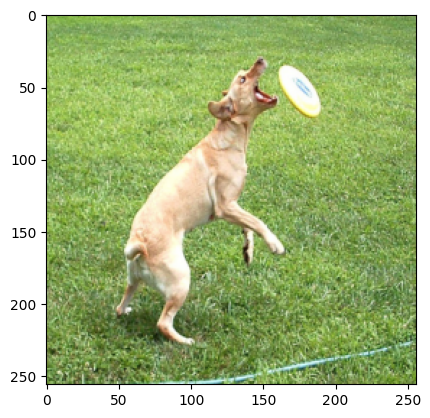

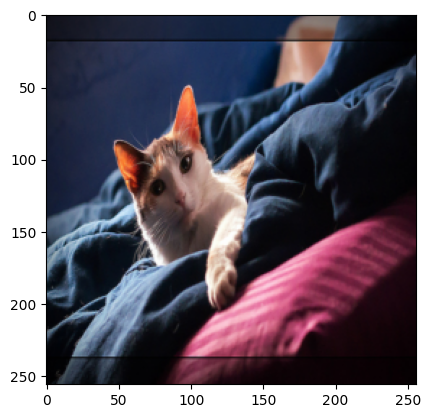

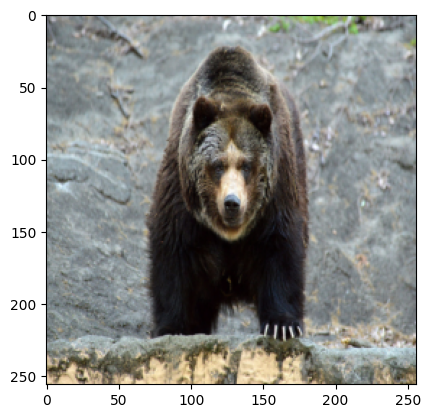

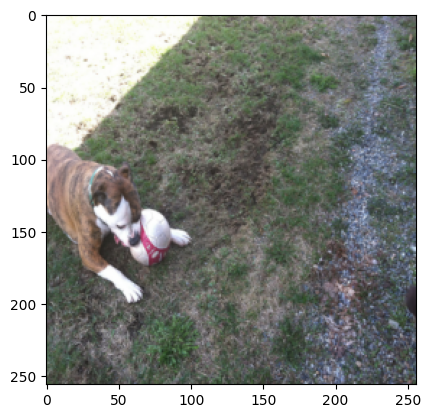

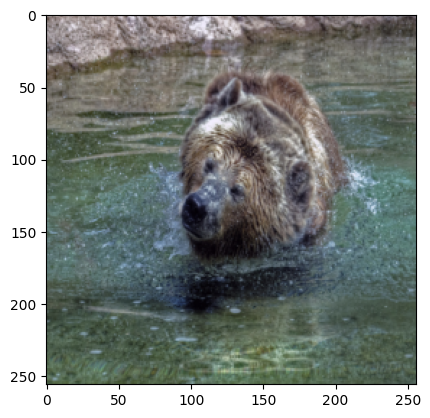

...

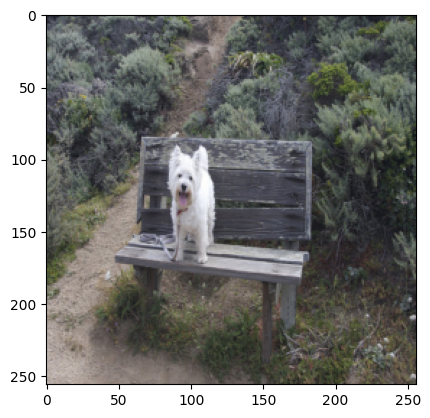

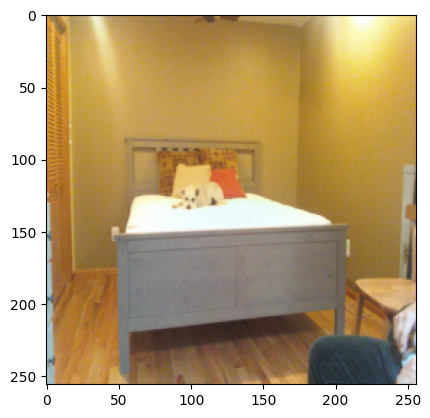

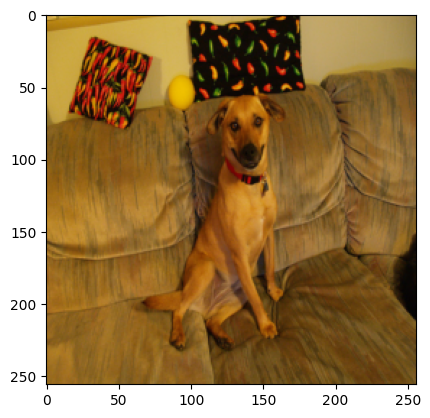

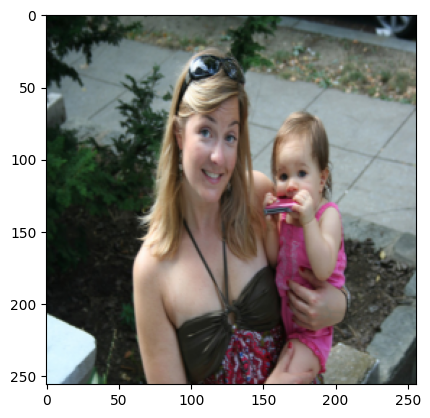

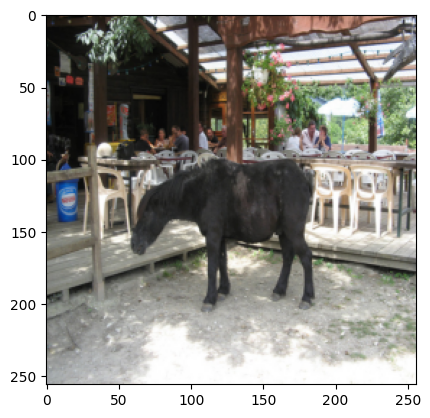

In [12]:
for i, img in enumerate(test_images):
    plt.imshow(img);#plt.title(class_names[train_labels[i]])
    plt.show()
    if i>10:break

In [56]:
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier
log = LogisticRegression().fit(emb_clip_train.reshape(emb_clip_train.shape[0], -1), train_labels)

In [14]:
from sklearn.metrics import accuracy_score

print(accuracy_score(cat.predict(emb_clip_train.reshape(emb_clip_train.shape[0],-1)),train_labels))

1.0


In [15]:
test_labels= log.predict(emb_clip_test.reshape(emb_clip_test.shape[0],-1))

In [45]:
class DF(Dataset):
    def __init__(self, embeds, labels, gt_boxes, proposals, proposal_costs, proposal_obj, is_test):
        self.embeds = embeds
        self.labels = labels
        self.y = gt_boxes
        self.proposals = proposals
        self.proposal_costs = proposal_costs
        self.proposal_obj = proposal_obj
        self.is_test = is_test

    def __len__(self):
        return len(self.embeds)

    def __getitem__(self, i):
        embed = torch.tensor(self.embeds[i], dtype=torch.float32)
        lab = torch.tensor(self.labels[i], dtype=torch.long)
    
        yi = torch.zeros(4, dtype=torch.float32) if self.is_test else torch.tensor(self.y[i], dtype=torch.float32)
    
        p = torch.tensor(self.proposals[i], dtype=torch.long)
        c = torch.tensor(self.proposal_costs[i], dtype=torch.float32)
        obj = torch.tensor(self.proposal_obj[i], dtype=torch.float32)
    
        return embed, lab, yi, p, c, obj

train_df = DF(
    emb_clip_train, train_labels, train_gt_boxes,
    proposals_train, proposal_cost_train, proposal_objness_train, False
)

test_df = DF(
    emb_clip_test, test_labels, None,
    proposals_test, proposal_cost_test, proposal_objness_test, True
)

train_dl = DataLoader(train_df, batch_size=16, shuffle=True, num_workers=4, pin_memory=True)
test_dl = DataLoader(test_df, batch_size=16, shuffle=False, num_workers=4, pin_memory=True)

for embed, labels, gt_boxes, proposals, costs, obj in train_dl:
    print(embed.shape)
    print(labels.shape)
    print(gt_boxes.shape)
    print(proposals.shape)
    print(costs.shape)
    print(obj.shape)
    break

torch.Size([16, 32, 768])
torch.Size([16])
torch.Size([16, 4])
torch.Size([16, 32, 4])
torch.Size([16, 32])
torch.Size([16, 32])


In [72]:
from sklearn.decomposition import PCA

Text(0.5, 1.0, 'number of classes, 12')

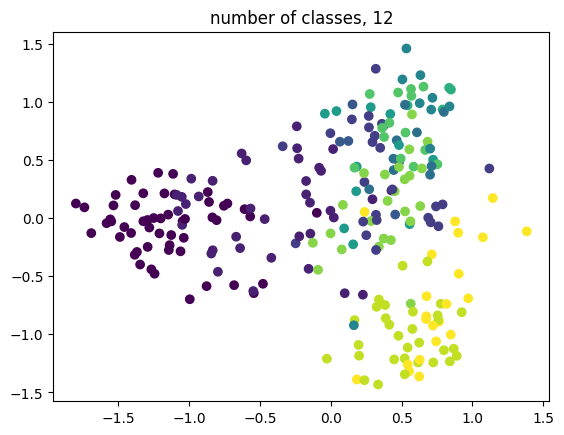

In [76]:
pca = PCA(n_components= 2).fit(emb_clip_train.reshape(emb_clip_train.shape[0], -1))
train_pca = pca.transform(emb_clip_train.reshape(emb_clip_train.shape[0],-1))
plt.scatter(train_pca[:,0],train_pca[:,1], c = train_labels)
plt.title(f"number of classes, {len(class_names)}",)

Text(0.5, 1.0, 'number of classes, 12')

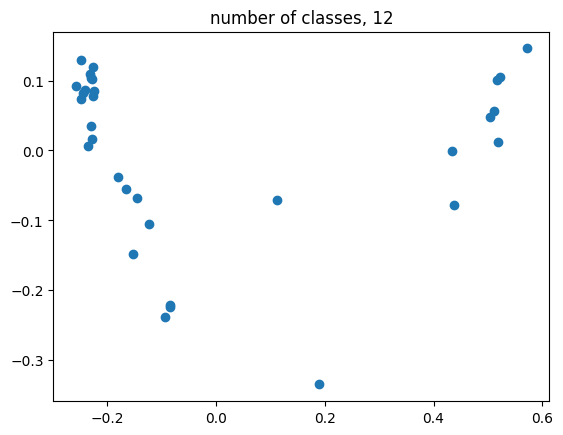

In [81]:
pca = PCA(n_components= 2).fit(emb_clip_train[2])
train_pca = pca.transform(emb_clip_train[2])
plt.scatter(train_pca[:,0],train_pca[:,1])
plt.title(f"number of classes, {len(class_names)}",)

In [21]:
def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    inter_width = max(0, x2 - x1)
    inter_height = max(0, y2 - y1)
    inter_area = inter_width * inter_height
    box1_area = (box1[2] - box1[0]) * (box1[3] - box1[1])
    box2_area = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union_area = box1_area + box2_area - inter_area
    if union_area == 0:
        return 0.0

    return inter_area / union_area


IoU: 0.1184


In [27]:
for i, box in enumerate(train_gt_boxes):
    iou = 0
    cost = 0
    obj = 0
    for idx, p_box in enumerate(proposals_train[i]):
        iou_i = calculate_iou(box, p_box)
        if iou_i > iou:
            iou = iou_i
            cost = proposal_cost_train[i][idx]
            obj = proposal_objness_train[i][idx]

    print("iou:", iou, "cost:", cost, "obj:", obj,
          "max_cost:", max(proposal_cost_train[i]),
          "min_cost:", min(proposal_cost_train[i]),
          "mean_cost:", np.mean(proposal_cost_train[i]),
          "max_obj:", max(proposal_objness_train[i]),
          "min_obj:", min(proposal_objness_train[i]),
          "mean_obj:", np.mean(proposal_objness_train[i]))

    if i > 5:
        break

iou: 0.8549151696606786 cost: 0.20913696 obj: 0.82318515 max_cost: 0.60679626 min_cost: 0.011932373 mean_cost: 0.22958612 max_obj: 1.0 min_obj: 0.0 mean_obj: 0.53335255
iou: 0.9082956699227293 cost: 0.09613037 obj: 0.19289795 max_cost: 0.2885437 min_cost: 0.022018433 mean_cost: 0.11428261 max_obj: 1.0 min_obj: 0.0 mean_obj: 0.32981586
iou: 0.9063504063504063 cost: 0.29481506 obj: 0.42064005 max_cost: 0.9309082 min_cost: 0.020980835 mean_cost: 0.3274207 max_obj: 1.0 min_obj: 0.0 mean_obj: 0.3721789
iou: 0.8999737003594285 cost: 0.31329346 obj: 0.42708468 max_cost: 0.7734375 min_cost: 0.017456055 mean_cost: 0.24722528 max_obj: 1.0 min_obj: 0.0 mean_obj: 0.4354005
iou: 0.9326697892271663 cost: 0.026062012 obj: 0.5542159 max_cost: 0.15234375 min_cost: 0.012176514 mean_cost: 0.048433304 max_obj: 1.0 min_obj: 0.0 mean_obj: 0.5493681
iou: 0.8482328482328483 cost: 0.014678955 obj: 0.7642691 max_cost: 0.112579346 min_cost: 0.0035705566 mean_cost: 0.026351452 max_obj: 1.0 min_obj: 0.0 mean_obj: 

/tmp/ipykernel_49/3898267321.py:18: RuntimeWarning: overflow encountered in scalar add
  union_area = box1_area + box2_area - inter_area
/tmp/ipykernel_49/3898267321.py:18: RuntimeWarning: overflow encountered in scalar subtract
  union_area = box1_area + box2_area - inter_area
/tmp/ipykernel_49/3898267321.py:15: RuntimeWarning: overflow encountered in scalar multiply
  box2_area = (box2[2] - box2[0]) * (box2[3] - box2[1])


In [37]:
selected_proposals = []
selected_ids =[]
for i in range(len(proposals_test)):
    costs = proposal_cost_test[i]
    objs = proposal_objness_test[i]
    mean_cost = np.mean(costs)
    std_cost = np.std(costs) + 1e-8
    cost_score = np.exp(-0.5 * ((costs - mean_cost) / std_cost) ** 2)
    scores = 0.4 * cost_score + 0.6 * objs
    best_idx = np.argmax(scores)
    selected_ids.append(best_idx)
    selected_proposals.append(proposals_test[i][best_idx])
selected_proposals = np.array(selected_proposals)

In [44]:
sample_sub["pred_class"]= test_labels
sample_sub["choice"]=selected_ids
sample_sub["confidence"] =0.9999

In [45]:
sample_sub.to_csv("sub2.csv",index=False)

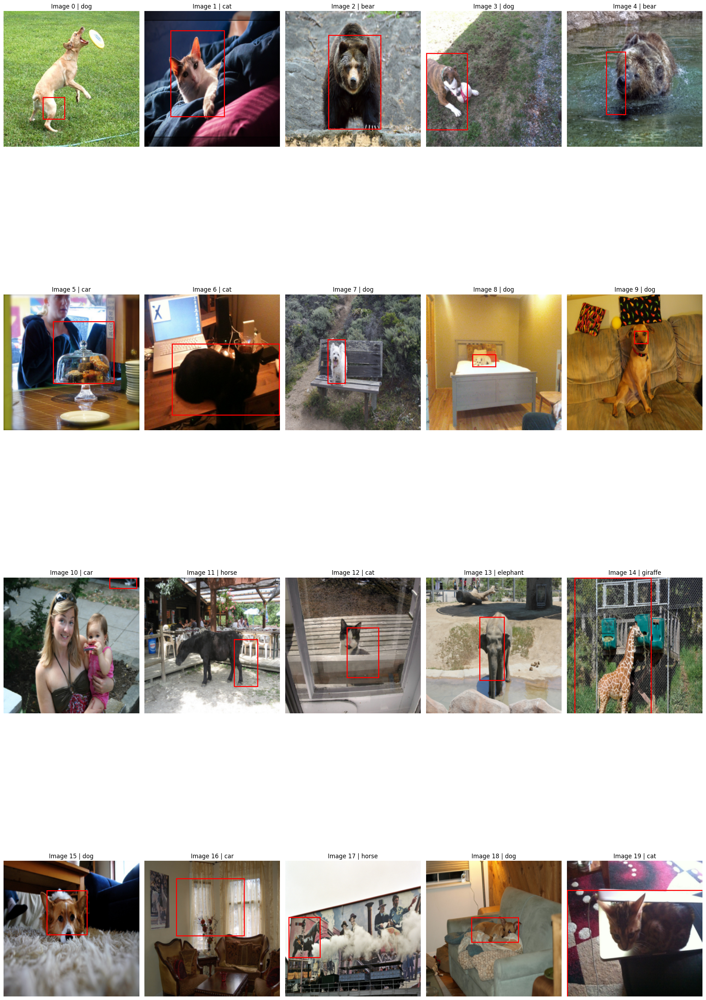

In [57]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, axes = plt.subplots(4, 5, figsize=(20, 35))
axes = axes.flatten()

for j, (idx, row) in enumerate(sample_sub.head(20).iterrows()):
    img = test_images[j]
    box = proposals_test[j][int(row["choice"])]
    cls = class_names[int(row["pred_class"])]
    axes[j].imshow(img)
    x1, y1, x2, y2 = box
    rect = patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        linewidth=2, edgecolor='red', facecolor='none'
    )
    axes[j].add_patch(rect)
    axes[j].set_title(f"Image {j} | {cls}")
    axes[j].axis("off")
plt.tight_layout()
plt.show()